# Kiểm tra số liệu depth — bấm từng ô

Notebook này **không tự bịa số**. Nó đọc file CSV mà simulator đã ghi ra
(`D:\replica_sim\results\...\per_sample.csv`) rồi tính lại đúng bằng hàm trong `eval_metrics.py`.

## Cách dùng

1. Mở file này trong VS Code hoặc Jupyter.
2. Bấm **Run** (hoặc Shift+Enter) **từ trên xuống**, từng ô một.
3. Các ô đầu chỉ đọc số đã có — nhanh, không chạy AI.
4. Ô cuối cùng mới chạy model **DepthART bản metric** (đo thẳng ra mét). Ô đó mặc định **tắt**.
   Muốn chạy thì đổi `RUN_METRIC = True` rồi bấm. Mất vài phút, và nên đóng Chrome trước
   (máy hết RAM thì Python chết không bắt được lỗi).

## Ba trường hợp đang có sẵn

| Tên thư mục | Nghĩa |
|---|---|
| `case_A` | Dùng đáp án làm bài. Phải ra sai số ~ 0. Nếu không, phép tính 2D→3D sai — đừng tin số model. |
| `case_B_clean` | DepthART bản relative (đoán tương đối rồi căn về mét), camera đặt đúng. |
| `case_B_noisy` | Giống trên, nhưng camera lệch nhẹ (2 cm / 0.5°). **Đây là số gần thực tế, dùng để báo cáo.** |

Số 2 mẫu thử bản metric (nếu có thư mục `results_smoke`) **không phải kết quả**. Đừng báo cáo.


In [9]:
# Ô 1 — tìm code và thư mục kết quả
from pathlib import Path
import sys

CANDIDATES = [
    Path.cwd(),
    Path.cwd() / "models" / "Depth3D_Localizer" / "simulation",
    Path(r"D:\Tài liệu lab HMI\FireGrounder-V3\models\Depth3D_Localizer\simulation"),
]
SIM = next((p for p in CANDIDATES if (p / "eval_metrics.py").is_file()), None)
if SIM is None:
    raise SystemExit(
        "Không thấy eval_metrics.py.\n"
        "Hãy mở notebook này từ repo FireGrounder-V3, hoặc từ thư mục simulation."
    )
if str(SIM) not in sys.path:
    sys.path.insert(0, str(SIM))

RESULTS = Path(r"D:\replica_sim\results")
SAMPLES = Path(r"D:\replica_sim\samples")
DATA = Path(r"D:\replica_sim\data\replica_pp\Replica")

print("code     :", SIM)
print("kết quả  :", RESULTS, "—", "có" if RESULTS.is_dir() else "KHÔNG CÓ")
print("mẫu test :", SAMPLES, "—", "có" if SAMPLES.is_dir() else "KHÔNG CÓ")
if RESULTS.is_dir():
    for d in sorted(p for p in RESULTS.iterdir() if p.is_dir()):
        csv = d / "per_sample.csv"
        n = sum(1 for _ in csv.open(encoding="utf-8")) - 1 if csv.is_file() else 0
        print(f"  {d.name:<24} {n} dòng")


code     : d:\Tài liệu lab HMI\FireGrounder-V3\models\Depth3D_Localizer\simulation
kết quả  : D:\replica_sim\results — có
mẫu test : D:\replica_sim\samples — có
  case_A                   400 dòng
  case_B_clean             400 dòng
  case_B_noisy             400 dòng


## Bảng tổng hợp

Ô dưới gọi **đúng hàm** `evaluate_case` của `eval_metrics.py` — cùng một công thức với lệnh
`python eval_metrics.py`. Không tính lại bằng công thức khác.

- **MAE**: sai số trung bình (mét). Càng nhỏ càng tốt.
- **Median**: điểm nằm giữa khi xếp sai số từ nhỏ đến lớn. Ít bị vài điểm tệ kéo lên.
- **P95**: 95% số điểm sai ít hơn mức này. Phần còn lại tệ hơn.
- **dưới 25 cm / 50 cm**: tỉ lệ điểm có sai số vị trí nhỏ hơn ngưỡng đó (1.0 = 100%).
- **AbsRel**: sai số khoảng cách chia cho khoảng cách thật, rồi lấy trung bình. 0.10 ≈ sai 10%.


In [10]:
# Ô 2 — tính lại metric từ CSV
from eval_metrics import discover_cases, evaluate_case, check_gate
import pandas as pd

cases = discover_cases(RESULTS)
summary = {}
for name, csv_path in cases:
    summary[name] = evaluate_case(name, csv_path)
summary["gate"] = check_gate(summary)

rows = []
for name, block in summary.items():
    if not name.startswith("case_"):
        continue
    pos, dep = block["position_3d"], block["depth"]
    rows.append({
        "case": name,
        "n": pos["n"],
        "MAE_m": pos.get("mae"),
        "Median_m": pos.get("median"),
        "P95_m": pos.get("p95"),
        "duoi_25cm": pos.get("le_0_25m"),
        "duoi_50cm": pos.get("le_0_50m"),
        "AbsRel": dep.get("absrel"),
        "depth_MAE_m": dep.get("mae"),
        "ghi_chu": dep.get("note"),
    })

bang = pd.DataFrame(rows).set_index("case")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
bang.round(4)


,n,MAE_m,Median_m,P95_m,duoi_25cm,duoi_50cm,AbsRel,depth_MAE_m,ghi_chu
case,,,,,,,,,
case_A,400,0.0000,0.0000,0.0000,1.0000,1.000,0.0000,0.0000,"Case A: depth_pred lấy từ depth GT — dùng để kiểm tra toán, KHÔNG phải đánh giá model"
case_B_clean,400,0.3012,0.2374,0.7787,0.5225,0.815,0.0956,0.2728,depth relative đã căn scale+shift trước khi so
case_B_noisy,400,0.3119,0.2459,0.7865,0.5075,0.815,0.0956,0.2728,depth relative đã căn scale+shift trước khi so


In [11]:
# Ô 3 — cổng kiểm tra phép tính (Case A)
print(summary["gate"]["message"])
print()
print("Nếu dòng trên KHÔNG phải GATE PASS, đừng tin các số Case B.")


✅ GATE PASS — Case A MAE 0.000 cm < 1 cm: số Case B đáng tin.

Nếu dòng trên KHÔNG phải GATE PASS, đừng tin các số Case B.


## Tách theo khoảng cách và theo vùng ảnh

Càng xa camera, sai số thường càng lớn. Nhóm nào có ít hơn 20 điểm thì **đừng kết luận** từ nhóm đó.

`center` = điểm nằm trong nửa giữa ảnh. `border` = phần còn lại.
Số đo được: nhóm giữa sai **nhiều hơn** nhóm rìa, trái với lý thuyết "rìa bị phóng đại".
Lý do đã kiểm: điểm giữa ảnh ở **xa hơn** (nhìn xuyên phòng), mà DepthART càng xa càng sai.
Vì vậy cột `center` / `border` hiện **bị lẫn với khoảng cách** — đừng đọc nó như "giữa ảnh khó hơn".


In [12]:
# Ô 4 — sai số theo khoảng cách và theo vùng ảnh
try:
    from IPython.display import display
except ImportError:
    display = print

dist_rows = []
reg_rows = []
for name, block in summary.items():
    if not name.startswith("case_"):
        continue
    pos = block["position_3d"]
    for bucket, st in pos.get("by_distance", {}).items():
        dist_rows.append({
            "case": name, "khoang": bucket, "n": st["n"],
            "MAE_m": st["mae"], "canh_bao": st.get("warning", ""),
        })
    for region in ("center", "border"):
        st = pos.get("by_region", {}).get(region, {})
        reg_rows.append({
            "case": name, "vung": region, "n": st.get("n"),
            "MAE_m": st.get("mae"), "canh_bao": st.get("warning", ""),
        })

print("Theo khoảng cách")
display(pd.DataFrame(dist_rows).round(4))
print("Theo vùng ảnh")
display(pd.DataFrame(reg_rows).round(4))


Theo khoảng cách


,case,khoang,n,MAE_m,canh_bao
0,case_A,0-2m,71,0.0000,
1,case_A,2-4m,273,0.0000,
2,case_A,4-6m,56,0.0000,
3,case_B_clean,0-2m,71,0.2473,
4,case_B_clean,2-4m,273,0.2649,
5,case_B_clean,4-6m,56,0.5460,
6,case_B_noisy,0-2m,71,0.2545,
7,case_B_noisy,2-4m,273,0.2774,
8,case_B_noisy,4-6m,56,0.5532,


Theo vùng ảnh


,case,vung,n,MAE_m,canh_bao
0,case_A,center,222,0.0000,
1,case_A,border,178,0.0000,
2,case_B_clean,center,222,0.3429,
3,case_B_clean,border,178,0.2490,
4,case_B_noisy,center,222,0.3527,
5,case_B_noisy,border,178,0.2611,


## Biểu đồ

Ba hình: sai số theo khoảng cách, giữa ảnh so với rìa, và MAE / Median / P95.


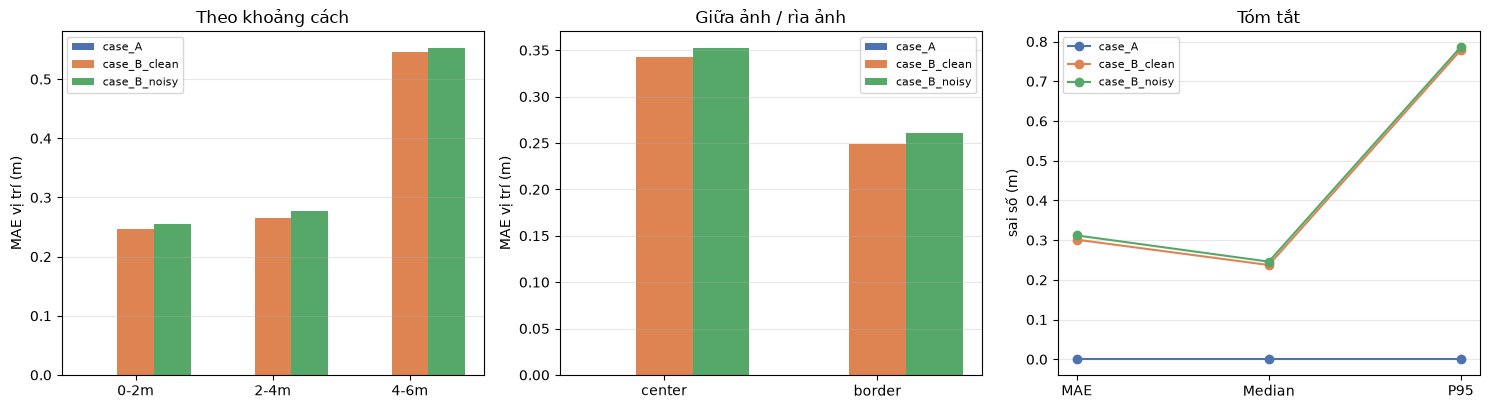

In [13]:
# Ô 5 — vẽ
import matplotlib.pyplot as plt
import numpy as np

names = [k for k in summary if k.startswith("case_")]
colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#CCB974"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

ax = axes[0]
width = 0.8 / max(len(names), 1)
buckets = ["0-2m", "2-4m", "4-6m"]
for i, name in enumerate(names):
    bd = summary[name]["position_3d"].get("by_distance", {})
    ys = [bd.get(b, {}).get("mae") or 0 for b in buckets]
    ax.bar(np.arange(len(buckets)) + i * width, ys, width=width,
           label=name, color=colors[i % len(colors)])
ax.set_xticks(np.arange(len(buckets)) + width * (len(names) - 1) / 2)
ax.set_xticklabels(buckets)
ax.set_ylabel("MAE vị trí (m)")
ax.set_title("Theo khoảng cách")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)

ax = axes[1]
for i, name in enumerate(names):
    br = summary[name]["position_3d"].get("by_region", {})
    ys = [br.get(r, {}).get("mae") or 0 for r in ("center", "border")]
    ax.bar(np.arange(2) + i * width, ys, width=width,
           label=name, color=colors[i % len(colors)])
ax.set_xticks(np.arange(2) + width * (len(names) - 1) / 2)
ax.set_xticklabels(["center", "border"])
ax.set_ylabel("MAE vị trí (m)")
ax.set_title("Giữa ảnh / rìa ảnh")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)

ax = axes[2]
for i, name in enumerate(names):
    st = summary[name]["position_3d"]
    ys = [st.get(k) for k in ("mae", "median", "p95")]
    if all(y is not None for y in ys):
        ax.plot([0, 1, 2], ys, "o-", label=name, color=colors[i % len(colors)])
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["MAE", "Median", "P95"])
ax.set_ylabel("sai số (m)")
ax.set_title("Tóm tắt")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()


## Tự kiểm tra bằng tay

Đổi `CASE` rồi chạy lại ô này. Ba số in ra phải **khớp** hàng tương ứng ở bảng ô 2.

`err` trong CSV đã là khoảng cách 3D (mét), không âm. MAE = trung bình cột đó.


In [14]:
# Ô 6 — đối chiếu tay trên 1 case
CASE = "case_B_noisy"   # đổi thành case_A hoặc case_B_clean rồi chạy lại ô này

df = pd.read_csv(RESULTS / CASE / "per_sample.csv")
print(f"{CASE}: {len(df)} dòng")
print(f"  MAE tay     = {df['err'].mean():.4f} m")
print(f"  Median tay  = {df['err'].median():.4f} m")
print(f"  P95 tay     = {df['err'].quantile(0.95):.4f} m")
may = summary[CASE]["position_3d"]
print(f"  MAE script  = {may['mae']:.4f} m")
print(f"  khớp MAE    = {abs(df['err'].mean() - may['mae']) < 1e-9}")
print()
print("10 điểm sai nhiều nhất:")
cols = ["sample_id", "scene", "region", "depth_gt", "depth_pred", "depth_err", "err"]
df.nlargest(10, "err")[cols].round(4)


case_B_noisy: 400 dòng
  MAE tay     = 0.3119 m
  Median tay  = 0.2459 m
  P95 tay     = 0.7865 m
  MAE script  = 0.3119 m
  khớp MAE    = True

10 điểm sai nhiều nhất:


,sample_id,scene,region,depth_gt,depth_pred,depth_err,err
211,replica_pp_office4_0007,office4,center,5.5619,4.2848,-1.2772,1.2858
154,replica_pp_office3_0001,office3,border,4.3191,3.3639,-0.9552,1.2416
220,replica_pp_office4_0016,office4,border,1.6339,0.6703,-0.9636,1.2333
254,replica_pp_office4_0050,office4,center,5.5460,4.3257,-1.2204,1.2305
246,replica_pp_office4_0042,office4,center,5.3793,4.2221,-1.1572,1.1668
169,replica_pp_office3_0016,office3,border,4.6358,3.6668,-0.9691,1.1305
216,replica_pp_office4_0012,office4,center,5.4414,4.3141,-1.1273,1.1297
191,replica_pp_office3_0038,office3,border,2.5681,3.4259,0.8578,0.9935
162,replica_pp_office3_0009,office3,center,2.4686,3.3767,0.9081,0.9737
236,replica_pp_office4_0032,office4,center,5.2003,4.2449,-0.9553,0.9562


## (Tuỳ chọn) Chấm DepthART bản metric

Bản **relative** (số ở trên) đoán tương đối rồi căn cho khớp mét.
Bản **metric** đoán thẳng ra mét, cần thông số ống kính — simulator đã lấy từ `cam_params.json`.

Ô dưới **không chạy** nếu bạn để `RUN_METRIC = False`.
Khi bật:

- mất khoảng vài phút (khoảng 80 ảnh, mỗi ảnh ~2 giây trên CPU),
- ghi vào `case_B_metric_clean` và `case_B_metric_noisy`,
- xong thì **chạy lại ô 2** để thấy hai hàng mới trên bảng.

Chưa chạy ô này thì **chưa có số metric**. Đừng điền số vào báo cáo.


In [ ]:
# Ô 7 — chấm bản metric (tắt mặc định)
RUN_METRIC = False
LIMIT = None          # đặt 20 nếu chỉ muốn thử nhanh; None = hết 400 mẫu
POSE_MODES = ("clean", "noisy")

import subprocess
import sys as _sys

if not RUN_METRIC:
    print("Đang tắt. Đổi RUN_METRIC = True rồi chạy lại ô này khi muốn chấm bản metric.")
else:
    if not SAMPLES.is_dir() or not DATA.is_dir():
        raise SystemExit(f"Thiếu dữ liệu.\n  samples: {SAMPLES}\n  data: {DATA}")
    for mode in POSE_MODES:
        out = RESULTS / f"case_B_metric_{mode}"
        cmd = [
            _sys.executable, str(SIM / "run_eval.py"),
            "--case", "B", "--pose-mode", mode,
            "--depth-model", "metric", "--depthart-encoder", "s",
            "--samples", str(SAMPLES), "--data-dir", str(DATA),
            "--source", "replica_pp", "--output", str(out), "--seed", "42",
        ]
        if LIMIT:
            cmd += ["--limit", str(LIMIT)]
        print("\n>>>", " ".join(cmd), flush=True)
        proc = subprocess.run(cmd)
        print(f"exit = {proc.returncode}")
        if proc.returncode != 0:
            raise SystemExit("run_eval thất bại — xem log phía trên. Chưa có số để báo cáo.")
    print("\nXong. Chạy lại ô 2 để cập nhật bảng.")


## Xem lệch trên ảnh

Bản đồ khoảng cách **là một tấm ảnh**: mỗi điểm ảnh một số mét. Không cần mô hình 3D.

Ô dưới vẽ 4 cột cho mỗi khung hình:

1. **Ảnh thật** — chấm tròn là điểm đã chấm. Số cạnh chấm là sai số vị trí 3D (mét).
2. **Khoảng cách thật** — càng vàng càng xa, càng tím càng gần.
3. **Khoảng cách model đoán** — cùng thang màu với cột 2, nên nhìn là thấy chỗ khác.
4. **Chỗ lệch** — xanh dương = model đoán **gần hơn** thật. Đỏ = model đoán **xa hơn** thật.
   Trắng = gần đúng. Thanh màu ghi đơn vị mét.

Ô này **chạy model** (bản relative, cùng bản đã ra số 0.31 m). Mỗi khung hình khoảng 1 giây.
Mặc định 2 khung hình. Đổi `N_FRAMES` nếu muốn xem thêm. Đóng Chrome nếu máy báo hết RAM.


Xem các khung: [('office4', 10), ('office3', 3)]
[DepthBackend] Loaded: DepthART-MNV4-S @ 224px  [CPU]  (cpu)
model: DepthART-MNV4-S @ 224px  [CPU]


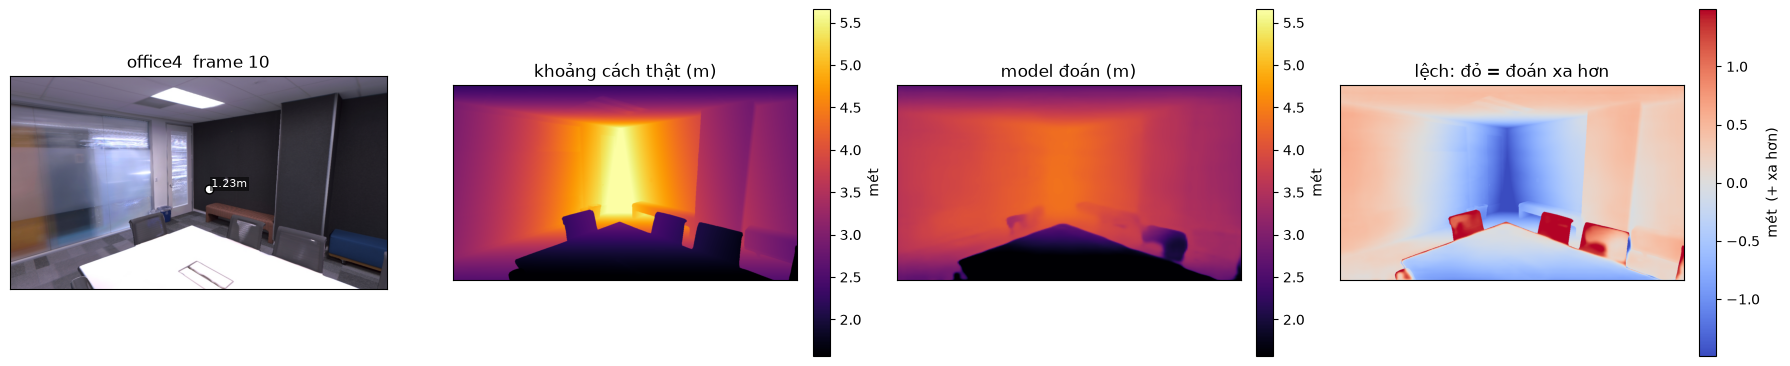

  office4 frame 10: lệch khoảng cách trung bình 0.446 m trên 816000 điểm ảnh hợp lệ (âm = gần hơn thật, dương = xa hơn thật)


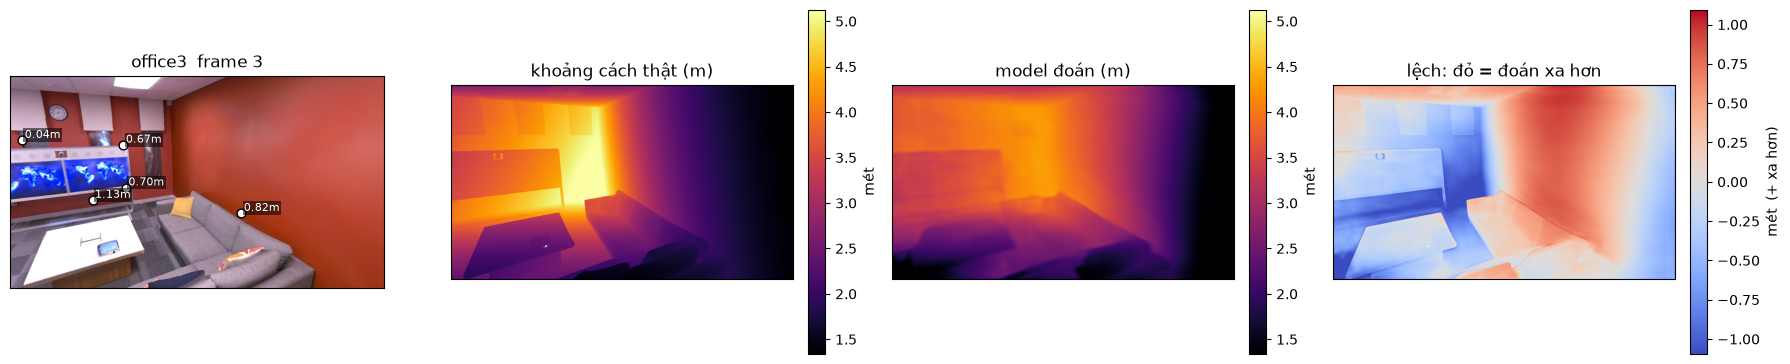

  office3 frame 3: lệch khoảng cách trung bình 0.436 m trên 815962 điểm ảnh hợp lệ (âm = gần hơn thật, dương = xa hơn thật)


In [15]:
# Ô 8 — xem model lệch ở đâu trên ảnh
N_FRAMES = 2          # số khung hình muốn xem
CASE = "case_B_noisy" # điểm chấm lấy từ case này (đã có sẵn, không chạy lại)
PICK = None           # None = lấy khung có điểm sai nhiều nhất.
                      # Hoặc điền tay, ví dụ: [("office0", 0), ("room1", 12)]

import sys as _sys
from pathlib import Path as _Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

_parent = str(SIM.parent)
if _parent not in _sys.path:
    _sys.path.insert(0, _parent)

from utils import load_depth_map, align_scale_shift
from depth_model import DepthBackend

pts = pd.read_csv(RESULTS / CASE / "per_sample.csv")
if PICK is None:
    worst = (pts.groupby(["scene", "frame"])["err"]
                .mean().sort_values(ascending=False).head(N_FRAMES))
    picks = [(s, int(f)) for s, f in worst.index]
else:
    picks = list(PICK)[:N_FRAMES]
print("Xem các khung:", picks)

backend = DepthBackend(prefer="depthart", depthart_encoder="MNV4-S")
backend.load()
print("model:", backend.model_name)

for scene, frame in picks:
    sub = pts[(pts["scene"] == scene) & (pts["frame"] == frame)]
    if sub.empty:
        print(f"  không có điểm test nào ở {scene} frame {frame}")
        continue
    row0 = sub.iloc[0]
    sid = row0["sample_id"]
    import json
    meta = json.loads(next(SAMPLES.glob(f"{sid}.json")).read_text(encoding="utf-8"))

    rgb = np.asarray(Image.open(meta["frame_path"]).convert("RGB"))
    gt = load_depth_map(meta["depth_path"], scale=meta["depth_scale"])
    pred_raw = np.asarray(backend.infer_path(meta["frame_path"]), dtype=np.float32)
    if pred_raw.shape != gt.shape:
        raise SystemExit(f"Sai kích thước: model {pred_raw.shape} vs GT {gt.shape}")
    ss = align_scale_shift(pred_raw, gt)
    pred = ss.scale * pred_raw + ss.shift

    err = pred - gt
    show = np.isfinite(gt) & (gt > 0) & np.isfinite(pred) & (pred > 0)
    err_show = np.where(show, err, np.nan)
    finite = err_show[np.isfinite(err_show)]
    lim = float(np.percentile(np.abs(finite), 98)) if finite.size else 1.0
    lim = max(lim, 0.05)

    fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
    axes[0].imshow(rgb)
    axes[0].set_title(f"{scene}  frame {frame}")
    for _, r in sub.iterrows():
        meta_i = json.loads((SAMPLES / f"{r['sample_id']}.json").read_text(encoding="utf-8"))
        u, v = meta_i["pixel"]
        axes[0].scatter([u], [v], s=40, c="white", edgecolors="black")
        axes[0].text(u + 8, v - 8, f"{r['err']:.2f}m", color="white", fontsize=8,
                     bbox=dict(facecolor="black", alpha=0.55, pad=1, edgecolor="none"))

    vmin = float(np.nanpercentile(gt[gt > 0], 2))
    vmax = float(np.nanpercentile(gt[gt > 0], 98))
    im1 = axes[1].imshow(np.where(gt > 0, gt, np.nan), cmap="inferno", vmin=vmin, vmax=vmax)
    axes[1].set_title("khoảng cách thật (m)")
    im2 = axes[2].imshow(np.where(pred > 0, pred, np.nan), cmap="inferno", vmin=vmin, vmax=vmax)
    axes[2].set_title("model đoán (m)")
    im3 = axes[3].imshow(err_show, cmap="coolwarm", vmin=-lim, vmax=lim)
    axes[3].set_title("lệch: đỏ = đoán xa hơn")
    for ax, im, label in (
        (axes[1], im1, "mét"),
        (axes[2], im2, "mét"),
        (axes[3], im3, "mét  (+ xa hơn)"),
    ):
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label(label)
    for ax in axes:
        ax.set_xticks([])
        ax.set_yticks([])
    fig.tight_layout()
    plt.show()

    ok = finite
    print(f"  {scene} frame {frame}: lệch khoảng cách trung bình "
          f"{np.mean(np.abs(ok)):.3f} m trên {ok.size} điểm ảnh hợp lệ "
          f"(âm = gần hơn thật, dương = xa hơn thật)")
